# data exploration

In [143]:
from __future__ import print_function
import numpy as np
from scipy import stats
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_rows', None)
dataset=pd.read_csv('merged_dataset.csv')


In [144]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6673 entries, 0 to 6672
Data columns (total 33 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   #chr                        6673 non-null   object 
 1   pos(1-based)                6673 non-null   int64  
 2   ref                         6673 non-null   object 
 3   alt                         6673 non-null   object 
 4   aaref                       6132 non-null   object 
 5   aaalt                       6132 non-null   object 
 6   aapos                       6673 non-null   int64  
 7   genename                    6673 non-null   object 
 8   REVEL_score                 6673 non-null   float64
 9   AlphaMissense_score         6673 non-null   float64
 10  CADD_phred                  6673 non-null   float64
 11  ClinPred_score              6673 non-null   float64
 12  BayesDel_addAF_score        6673 non-null   float64
 13  MetaRNN_score               6673 

In [145]:
dataset.head()

,#chr,pos(1-based),ref,alt,aaref,aaalt,aapos,genename,REVEL_score,AlphaMissense_score,...,Polyphen2_HDIV_score,nuc_before,nuc_ref,nuc_after,mw_change,hydro_change,polarity_change,label,ReviewStatus,ClinSigSimple
0,1,9710459,C,A,P,T,2,PIK3CD,0.166,0.1775,...,0.971,GGATG,C,CCCCT,4.0,0.9,1.0,Benign,reviewed by expert panel,0.0
1,1,9710567,C,T,R,C,38,PIK3CD,0.238,0.0757,...,0.232,TGTCC,C,GCAAT,-53.0,7.0,-1.0,Benign,reviewed by expert panel,0.0
2,1,9715640,G,A,E,K,81,PIK3CD,0.661,0.6296,...,1.000,AGCAA,G,AGCTG,-0.9,-0.4,0.0,Pathogenic,reviewed by expert panel,1.0
3,1,9715849,G,A,G,D,124,PIK3CD,0.244,0.5383,...,1.000,CGCAG,G,CCTCC,58.0,-3.1,1.0,Pathogenic,reviewed by expert panel,1.0
4,1,9715914,T,A,F,I,146,PIK3CD,0.165,0.1385,...,0.046,GCCAA,T,TCTGC,-34.0,1.7,0.0,Benign,reviewed by expert panel,0.0


In [146]:
dataset.shape

(6673, 33)

In [147]:
dataset['label'].value_counts()

label
Pathogenic    5143
Benign        1468
Name: count, dtype: int64

In [148]:
# print(dataset.isna().sum())


In [149]:
df = dataset.dropna()
# print(df.isna().sum())


In [150]:
# df['genename'].value_counts()

In [151]:
# df['genename'].dtype

In [152]:
df = df.astype({col: 'string' for col in df.select_dtypes(include='object').columns})

In [153]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 6070 entries, 0 to 6672
Data columns (total 33 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   #chr                        6070 non-null   string 
 1   pos(1-based)                6070 non-null   int64  
 2   ref                         6070 non-null   string 
 3   alt                         6070 non-null   string 
 4   aaref                       6070 non-null   string 
 5   aaalt                       6070 non-null   string 
 6   aapos                       6070 non-null   int64  
 7   genename                    6070 non-null   string 
 8   REVEL_score                 6070 non-null   float64
 9   AlphaMissense_score         6070 non-null   float64
 10  CADD_phred                  6070 non-null   float64
 11  ClinPred_score              6070 non-null   float64
 12  BayesDel_addAF_score        6070 non-null   float64
 13  MetaRNN_score               6070 non-n

In [154]:
# df['genename'].dtype

In [155]:
df['label'].value_counts()

label
Pathogenic    4612
Benign        1458
Name: count, dtype: Int64

In [156]:
df_cftr = df[df['genename'].str.contains('CFTR', na=False)]

In [157]:
df_cftr['label'].value_counts()

label
Pathogenic    171
Name: count, dtype: Int64

In [158]:
# df['genename'].value_counts()

In [159]:
df_pah = df[df['genename'].str.contains('PAH', na=False)]
df_pah['genename'].value_counts()



genename
PAH    336
Name: count, dtype: Int64

In [160]:
df_pah['label'].value_counts()

label
Pathogenic    335
Benign          1
Name: count, dtype: Int64

In [161]:
df_Hereditary = df[df['genename'].str.contains('BRCA1' or 'BRCA2' or 'TP53' or 'PALB2' or 'ATM' or 'CHEK2' or 'MLH1' or 'MSH2' or 'MSH6' or 'PMS2' or 'APC' or 'PTEN' or 'CDH1'or 'STK11'or 'RAD51C'or 'RAD51D'or 'BARD1'or 'BRIP1', na=False)]
df_Hereditary['genename'].value_counts()



genename
BRCA1    593
Name: count, dtype: Int64

In [162]:
df_Hereditary['label'].value_counts()

label
Pathogenic    457
Benign        136
Name: count, dtype: Int64

In [163]:
df.head()

,#chr,pos(1-based),ref,alt,aaref,aaalt,aapos,genename,REVEL_score,AlphaMissense_score,...,Polyphen2_HDIV_score,nuc_before,nuc_ref,nuc_after,mw_change,hydro_change,polarity_change,label,ReviewStatus,ClinSigSimple
0,1,9710459,C,A,P,T,2,PIK3CD,0.166,0.1775,...,0.971,GGATG,C,CCCCT,4.0,0.9,1.0,Benign,reviewed by expert panel,0.0
1,1,9710567,C,T,R,C,38,PIK3CD,0.238,0.0757,...,0.232,TGTCC,C,GCAAT,-53.0,7.0,-1.0,Benign,reviewed by expert panel,0.0
2,1,9715640,G,A,E,K,81,PIK3CD,0.661,0.6296,...,1.000,AGCAA,G,AGCTG,-0.9,-0.4,0.0,Pathogenic,reviewed by expert panel,1.0
3,1,9715849,G,A,G,D,124,PIK3CD,0.244,0.5383,...,1.000,CGCAG,G,CCTCC,58.0,-3.1,1.0,Pathogenic,reviewed by expert panel,1.0
4,1,9715914,T,A,F,I,146,PIK3CD,0.165,0.1385,...,0.046,GCCAA,T,TCTGC,-34.0,1.7,0.0,Benign,reviewed by expert panel,0.0


# Graphs

## general data (all included)

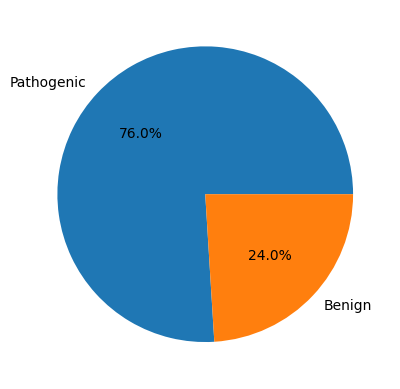

In [188]:
plt.pie(df['label'].value_counts().values,autopct="%1.1f%%",labels=df['label'].value_counts().keys().tolist())
plt.savefig("generated_images/general_data_all.png", dpi=300, bbox_inches='tight')
plt.show()

---

### PAH

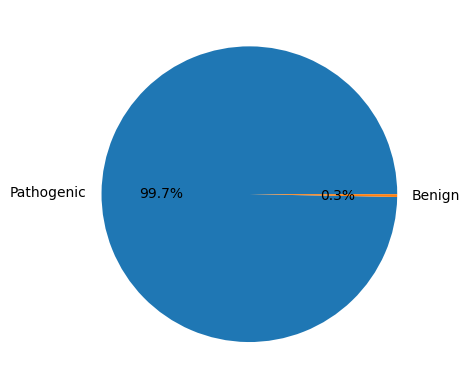

In [189]:
plt.pie(df_pah['label'].value_counts().values,autopct="%1.1f%%",labels=df_pah['label'].value_counts().keys().tolist())
plt.savefig("generated_images/PAH_data.png", dpi=300, bbox_inches='tight')
plt.show()



---

## CFTR

In [190]:
df_cftr['label'].value_counts().keys().tolist()

['Pathogenic']

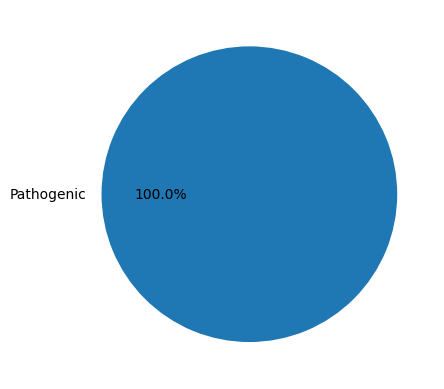

In [191]:
plt.pie(df_cftr['label'].value_counts().values,autopct="%1.1f%%",labels=df_cftr['label'].value_counts().keys().tolist())
plt.savefig("generated_images/CFTR_data.png", dpi=300, bbox_inches='tight')
plt.show()



---

## Hereditary DATA

In [192]:


df_Hereditary['label'].value_counts().keys().tolist()

['Pathogenic', 'Benign']

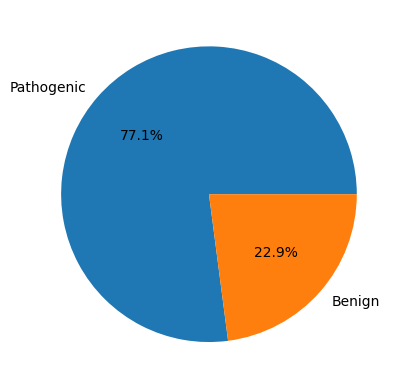

In [193]:
plt.pie(df_Hereditary['label'].value_counts().values,autopct="%1.1f%%",labels=df_Hereditary['label'].value_counts().keys().tolist())

plt.savefig("generated_images/hereditary_data.png", dpi=300, bbox_inches='tight')

plt.show()

In [194]:
from sklearn.preprocessing import LabelEncoder

df['label'] = LabelEncoder().fit_transform(df['label'])

In [195]:
categorical_cols = ['ref', 'alt', 'nuc_before', 'nuc_after', 'ReviewStatus']


# Keep numeric columns separate
numeric_cols = df.drop(columns=categorical_cols + ['label'])

# One-hot encode selected categorical columns
encoded_cats = pd.get_dummies(df[categorical_cols], drop_first=True)

# Combine numeric + encoded categorical columns
X = pd.concat([numeric_cols, encoded_cats], axis=1)

In [196]:
# Separate target
y = df['label']

# Features
X = df.drop(columns=['label'])

# Encode everything non-numeric
X = pd.get_dummies(X, drop_first=True)

# Final check
print(X.select_dtypes(include=['object', 'string']).columns)

X = pd.get_dummies(df.drop(columns=['label']), drop_first=True)

Index([], dtype='object')


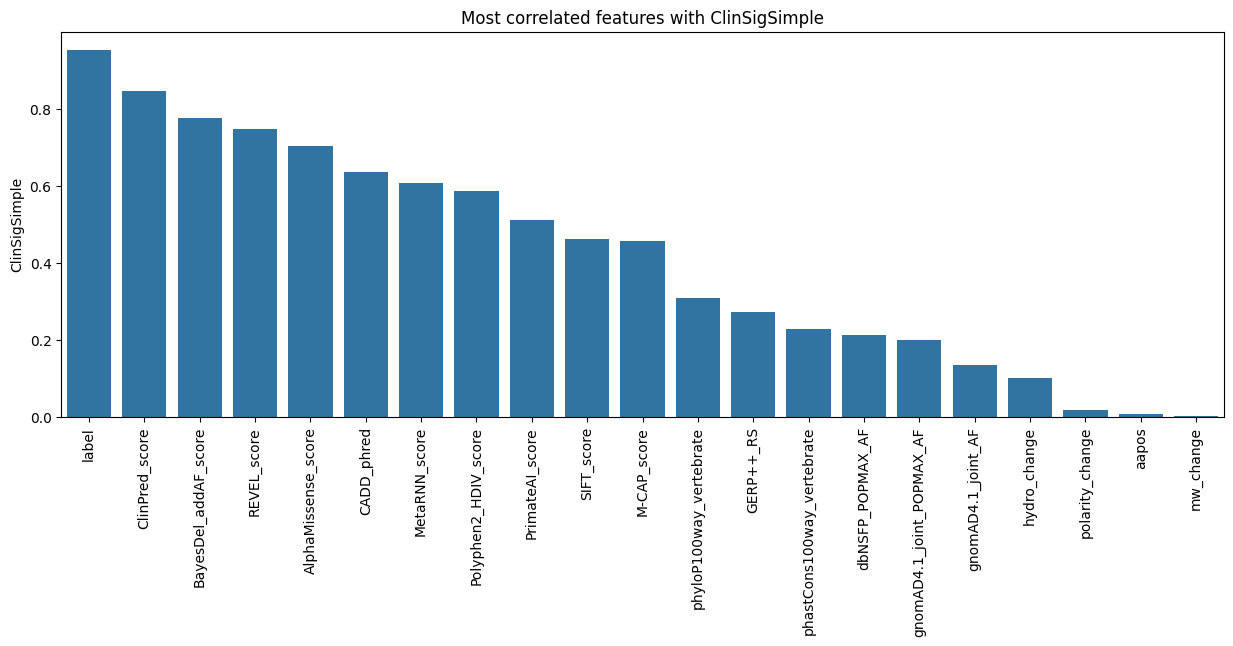

In [197]:



def show_corr(dataset, target_name, n_most=None):
    # Keep only numeric columns
    dataset = dataset.select_dtypes(include='number')

    # Safety check
    if target_name not in dataset.columns:
        raise ValueError(f"{target_name} is not numeric or not in dataset")


    if n_most is None:
        n_most = len(dataset.columns) - 1

    corr_matrix = dataset.corr().abs()

    most_correlated_features = (
        corr_matrix[target_name]
        .sort_values(ascending=False)
        .drop(target_name)
    )

    most_correlated_feature_names = most_correlated_features.index.values

    fig, ax = plt.subplots(figsize=(15, 5))
    plt.xticks(rotation=90)
    sns.barplot(x=most_correlated_feature_names, y=most_correlated_features)
    plt.title(f"Most correlated features with {target_name}")
    plt.savefig(f"generated_images/Most correlated features with {target_name}.png", dpi=300, bbox_inches='tight')

df_num1 = df.drop(['ReviewStatus','genename','pos(1-based)','#chr'],axis=1)
df_num = df_num1.select_dtypes(include='number')
    
show_corr(dataset=df_num, target_name='ClinSigSimple')



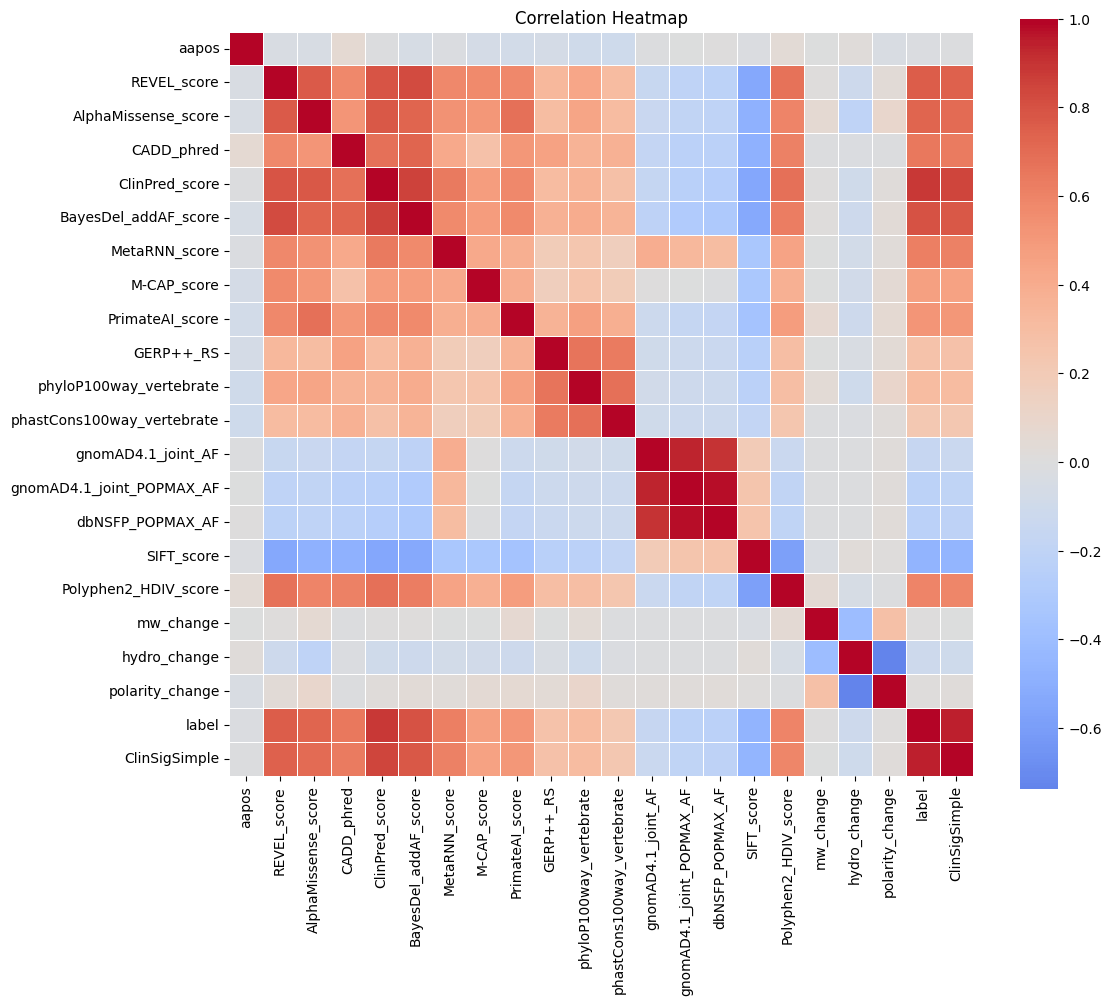

In [198]:
import seaborn as sns
import matplotlib.pyplot as plt

df_num1 = df.drop(['ReviewStatus','genename','pos(1-based)','#chr'],axis=1)
df_num = df_num1.select_dtypes(include='number')

plt.figure(figsize=(12, 10))

corr = df_num.corr()

sns.heatmap(
    corr,
    cmap='coolwarm',
    center=0,
    square=True,
    linewidths=0.5
)

title = "Correlation Heatmap"
plt.title(title)

plt.savefig(f"generated_images/{title}.png", dpi=300, bbox_inches='tight')

   
plt.show()